In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

import os
os.chdir(r"C:\Users\cebal\OneDrive\Documentos\Grandes Bases de Datos I")

In [2]:
col_names = ["Age", "Sex", "BP", "Cholesterol","Na_to_K","Drug"]
df = pd.read_csv("drugs.csv", header=None, names=col_names)
df = df.iloc[1:, :]
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
1,23,F,HIGH,HIGH,25.355,drugY
2,47,M,LOW,HIGH,13.093,drugC
3,47,M,LOW,HIGH,10.114,drugC
4,28,F,NORMAL,HIGH,7.798,drugX
5,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
196,56,F,LOW,HIGH,11.567,drugC
197,16,M,LOW,HIGH,12.006,drugC
198,52,M,NORMAL,HIGH,9.894,drugX
199,23,M,NORMAL,NORMAL,14.02,drugX


In [4]:
from sklearn import preprocessing

In [5]:
# Codificación de las variables cualitativas
le = preprocessing.LabelEncoder()

# transormacion de las variables
df["Sex"] = le.fit_transform(df["Sex"])
df["BP"] = le.fit_transform(df["BP"])
df["Cholesterol"] = le.fit_transform(df["Cholesterol"])
df["Drug"] = le.fit_transform(df["Drug"])
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
1,23,0,0,0,25.355,4
2,47,1,1,0,13.093,2
3,47,1,1,0,10.114,2
4,28,0,2,0,7.798,3
5,61,0,1,0,18.043,4
...,...,...,...,...,...,...
196,56,0,1,0,11.567,2
197,16,1,1,0,12.006,2
198,52,1,2,0,9.894,3
199,23,1,2,1,14.02,3


In [6]:
# Selección de las características
feature_cols = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]

X = df[feature_cols]
y = df["Drug"]

In [7]:
# Creación de las bases de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [8]:
# saga: Stochastic Average Gradient
# newton-cg: Newton
# liblinear: Library for large linear classification (Algoritmo Coordinate Descent)
# saga: Variante del método saga
# lbfgs: Limited-memory Broyden-Fletcher-Goldfarb-Shanno Algorithm

In [ ]:
Regresion Logistica con Solucionador (Solver): sag

In [15]:
model = LogisticRegression(solver="sag")
clf = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("--------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("--------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 0.25263109 -0.08397935  0.08662492  0.2907744  -0.54605106]
Pesos (Betas):  [[-0.02651411  0.16030874 -0.64557     0.05632821  0.10023294]
 [ 0.07160094 -0.04440322 -0.61803573 -0.00728641 -0.27744535]
 [-0.0036971   0.01063003  0.14295484 -0.27926705 -0.01603329]
 [ 0.00997615 -0.04657855  1.29197924  0.43007585 -0.11666405]
 [-0.05136588 -0.07995699 -0.17132835 -0.19985059  0.30990975]]
--------------------------------------------------
Precisión global:  0.7
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      1.00      0.50         2
           2       0.00      0.00      0.00         4
           3       0.79      0.85      0.81        13
           4       0.75      0.88      0.81        17

    accuracy                           0.70        40
   macro avg       0.37      0.55      0.43        40
weighted avg       0.59   

In [ ]:
Regresion Logistica con Solucionador (Solver): newton-cg

In [14]:
model = LogisticRegression(solver="newton-cg")
clf = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("--------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("--------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 14.90853999   0.85780302  10.22521729   6.21982836 -32.21138866]
Pesos (Betas):  [[-8.95983965e-02  3.53379996e-02 -2.31784807e+00 -4.79194281e-01
  -6.86706806e-01]
 [ 1.24914783e-01 -6.76062522e-02 -1.72802240e+00  8.89064907e-02
  -4.37699912e-01]
 [-2.61743813e-02 -8.10481817e-02  5.55740827e-01 -1.49450496e+00
  -6.06681677e-01]
 [-6.08499270e-03 -3.06185263e-01  3.06943884e+00  1.74851079e+00
  -5.82425907e-01]
 [-3.05700908e-03  4.19501697e-01  4.20690800e-01  1.36281956e-01
   2.31351430e+00]]
--------------------------------------------------
Precisión global:  0.95
--------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       0.50      1.00      0.67         2
           2       1.00      0.50      0.67         4
           3       1.00      1.00      1.00        13
           4       1.00      1.00      1.00        17

    accuracy      

In [ ]:
Regresion Logistica con Solucionador (Solver): liblinear

In [23]:
from sklearn.multiclass import OneVsRestClassifier
model = OneVsRestClassifier(LogisticRegression(solver="liblinear"))
clf = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# Impresión de interceptos y coeficientes
for i, estimador in enumerate(clf.estimators_):
    print(f"Intercepto de la clase {i}:", estimador.intercept_)
    print(f"Pesos (Betas) de la clase {i}:", estimador.coef_)
print("--------------------------------------------------")
# Evaluación de la precisión del modelo
score = model.score(X_test, y_test)
print("Precisión global:", score)
print("--------------------------------------------------")
# Reporte de clasificación
print(classification_report(y_test, y_pred, zero_division=0))

Intercepto de la clase 0: [2.40746561]
Pesos (Betas) de la clase 0: [[-0.02921407  0.44404599 -2.27567481 -0.39547958 -0.16499258]]
Intercepto de la clase 1: [-0.69169247]
Pesos (Betas) de la clase 1: [[ 0.10671426 -0.46849485 -2.51665437 -0.29172706 -0.42805268]]
Intercepto de la clase 2: [0.59552877]
Pesos (Betas) de la clase 2: [[-0.00239661  0.00501768 -0.05766121 -1.77734484 -0.18320195]]
Intercepto de la clase 3: [0.49274606]
Pesos (Betas) de la clase 3: [[ 0.00967804 -0.57176484  3.03029788  2.17470282 -0.46584305]]
Intercepto de la clase 4: [-4.53305879]
Pesos (Betas) de la clase 4: [[-0.04054753  0.05573547 -0.27251108 -0.44338566  0.44898139]]
--------------------------------------------------
Precisión global: 0.825
--------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.40      1.00      0.57         2
           2       0.00      0.00      0.00      

In [ ]:
Regresion Logistica con Solucionador (Solver): saga

In [24]:
model = LogisticRegression(solver="saga")
clf = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("--------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("--------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 0.12835198 -0.0528759   0.04094452  0.17573224 -0.29215283]
Pesos (Betas):  [[-0.0241303   0.09093704 -0.38624595  0.03701575  0.08720411]
 [ 0.06550313 -0.01942257 -0.38775928 -0.00395897 -0.26893367]
 [-0.00372293  0.00621798  0.06950605 -0.1478932  -0.01992306]
 [ 0.01342853 -0.02746503  0.85408847  0.23083671 -0.08005042]
 [-0.05107842 -0.05026742 -0.14958929 -0.11600028  0.28170304]]
--------------------------------------------------
Precisión global:  0.725
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      1.00      0.50         2
           2       0.00      0.00      0.00         4
           3       0.85      0.85      0.85        13
           4       0.76      0.94      0.84        17

    accuracy                           0.72        40
   macro avg       0.39      0.56      0.44        40
weighted avg       0.62 

In [ ]:
Regresion Logistica con Solucionador (Solver): lbfgs

In [25]:
model = LogisticRegression(solver="lbfgs")
clf = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("--------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("--------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 2.30379495 -0.56798231  1.04481646  1.46223146 -4.24286056]
Pesos (Betas):  [[-0.03543256  0.69128166 -2.9140636  -0.30412463  0.06589348]
 [ 0.11050398 -0.45753851 -2.74994219 -0.30718706 -0.27407026]
 [-0.02036465  0.1356119   1.17488441 -1.7572473   0.00538754]
 [-0.0121767  -0.55065662  4.02565322  2.83696335 -0.37094081]
 [-0.04253006  0.18130156  0.46346817 -0.46840436  0.57373004]]
--------------------------------------------------
Precisión global:  0.85
--------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.50      1.00      0.67         2
           2       1.00      0.25      0.40         4
           3       0.81      1.00      0.90        13
           4       0.94      0.88      0.91        17

    accuracy                           0.85        40
   macro avg       0.85      0.78      0.75        40
weighted avg       0.89  

In [ ]:
# El metodo que nos explica un mejor modelo es el Newton-cg al tener una presicion
# global del 95%

In [31]:
# Predicción de probabilidades para casos particulares
y_pred_probs = clf.predict_proba(X_test)
y_pred_probs[0:5]

array([[6.61627356e-06, 3.37754232e-05, 1.20371341e-03, 9.98299933e-01,
        4.55961868e-04],
       [7.01863068e-05, 3.39184076e-04, 6.66388834e-02, 3.97477844e-02,
        8.93203962e-01],
       [4.62349157e-04, 2.15701320e-04, 2.53479164e-01, 4.38464383e-01,
        3.07378403e-01],
       [2.34993133e-02, 1.07555237e-03, 2.74398307e-01, 6.48427369e-02,
        6.36184090e-01],
       [4.97532089e-06, 1.25850446e-11, 1.95272135e-07, 2.87092372e-13,
        9.99994829e-01]])

In [28]:
y_test[0:5]

59     3
41     4
35     3
103    2
185    4
Name: Drug, dtype: int64

In [29]:
y_test = y_test.to_numpy()
y_test[0:5]

array([3, 4, 3, 2, 4])

In [34]:
import numpy as np
y_pred_probs = np.round(y_pred_probs, 0)
y_pred_probs[0:5]

array([[0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.],
       [0., 0., 0., 0., 1.]])

In [37]:
# Graficación de la curva ROC y cálculo del área bajo ella
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

# Convertir las clases a formato binario
y_test_bin = label_binarize(y_test, classes=clf.classes_)

# fpr = false positive rate
# tpr = true positive rate
# thresholds = límites para valores de p

fpr = {}
tpr = {}
thresholds = {}
auc = {}

for i in range(len(clf.classes_)):
    fpr[i], tpr[i], thresholds[i] = roc_curve(
        y_test_bin[:, i], y_pred_probs[:, i]
    )
    auc[i] = roc_auc_score(y_test_bin[:, i], y_pred_probs[:, i])

print("AUC por clase:", auc)

AUC por clase: {0: 0.875, 1: 0.9736842105263158, 2: 0.5, 3: 0.9245014245014245, 4: 0.9194373401534528}


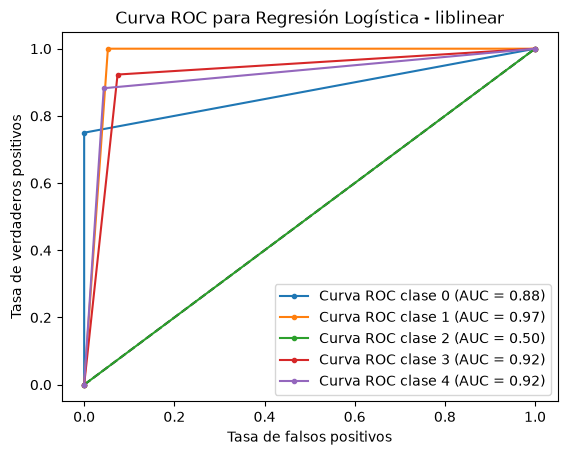

In [39]:
# Gráfica de la curva ROC para Regresión Logística
plt.plot([0, 1], [0, 1], 'k--')

for i in range(len(clf.classes_)):
    plt.plot(
        fpr[i],
        tpr[i],
        marker='.',
        label="Curva ROC clase %s (AUC = %0.2f)" % (clf.classes_[i], auc[i])
    )

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.title("Curva ROC para Regresión Logística - liblinear")
plt.show()